Data Visualizing and Interpreting

In [2]:
import pandas as pd


# Load the dataset
file_path = "water_potability.csv"
df = pd.read_csv(file_path)

# Show basic information and first few rows
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [3]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


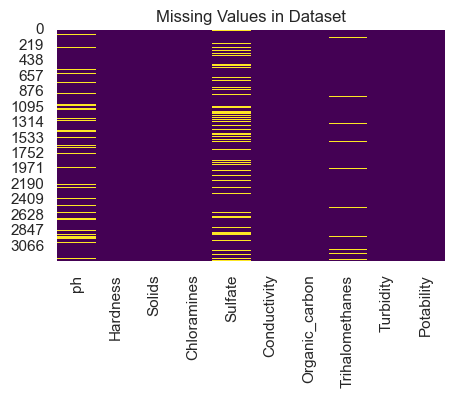

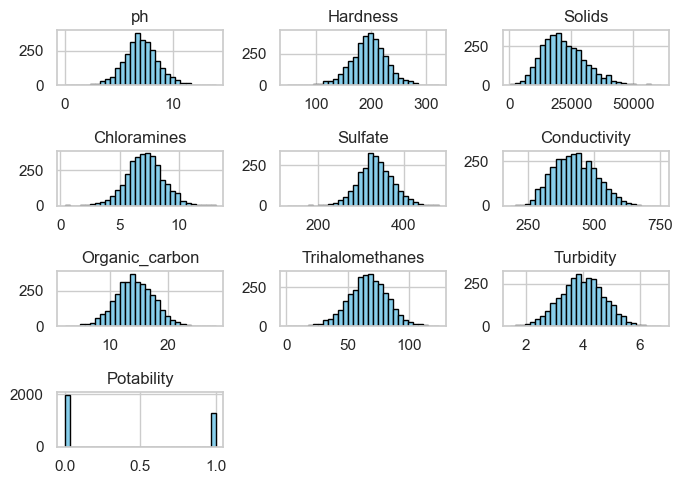

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set(style="whitegrid")

# Visualize missing values
plt.figure(figsize=(5, 3))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values in Dataset")
plt.show()

# Plot distribution of each feature
df.hist(bins=30, figsize=(7, 5), layout=(4, 3), color='skyblue', edgecolor='black')
plt.tight_layout()
plt.show()




Preprocessing 

In [5]:
# df_cleaned = df.dropna()
# df_cleaned

In [6]:
# Drop rows with any null values
df_cleaned = df.dropna()

# Check the new shape
print(f"Original shape: {df.shape}")
print(f"New shape after dropping nulls: {df_cleaned.shape}")


Original shape: (3276, 10)
New shape after dropping nulls: (2011, 10)


In [7]:
df_cleaned.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000
mean,7.085990,195.968072,21917.441374,7.134338,333.224672,426.526409,14.357709,66.400859,3.969729,0.403282
std,1.573337,32.635085,8642.239815,1.584820,41.205172,80.712572,3.324959,16.077109,0.780346,0.490678
min,0.227499,73.492234,320.942611,1.390871,129.000000,201.619737,2.200000,8.577013,1.450000,0.000000
25%,6.089723,176.744938,15615.665390,6.138895,307.632511,366.680307,12.124105,55.952664,3.442915,0.000000
50%,7.027297,197.191839,20933.512750,7.143907,332.232177,423.455906,14.322019,66.542198,3.968177,0.000000
75%,8.052969,216.441070,27182.587067,8.109726,359.330555,482.373169,16.683049,77.291925,4.514175,1.000000
max,14.000000,317.338124,56488.672413,13.127000,481.030642,753.342620,27.006707,124.000000,6.494749,1.000000


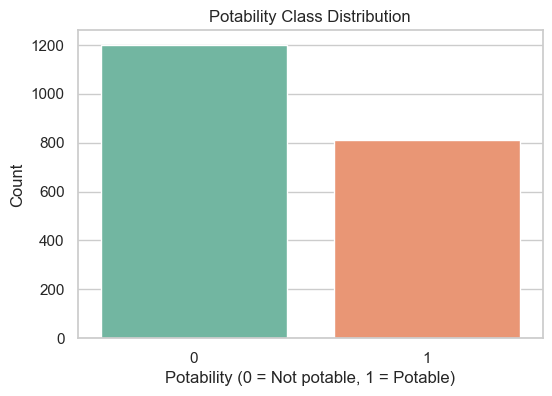

In [8]:
import warnings
warnings.filterwarnings("ignore")

plt.figure(figsize=(6, 4))
sns.countplot(x='Potability', data=df_cleaned, palette='Set2')
plt.title("Potability Class Distribution")
plt.xlabel("Potability (0 = Not potable, 1 = Potable)")
plt.ylabel("Count")
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Handle missing values by filling with the mean
df['ph'].fillna(df['ph'].mean(), inplace=True)
df['Sulfate'].fillna(df['Sulfate'].mean(), inplace=True)
df.dropna(inplace=True)

# Define features (X) and target (y)
X = df.drop('Potability', axis=1)
y = df['Potability']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier()
}



In [10]:
# Dictionary to store accuracy scores
accuracy_scores = {}

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores[name] = accuracy


In [11]:

# Create a DataFrame for comparison
accuracy_df = pd.DataFrame(list(accuracy_scores.items()), columns=['Model', 'Accuracy'])
accuracy_df_sorted = accuracy_df.sort_values(by='Accuracy', ascending=False)

# Print the sorted accuracy comparison table
print("Model Accuracy Comparison:")
print(accuracy_df_sorted)


Model Accuracy Comparison:
                 Model  Accuracy
2        Random Forest  0.669342
0  Logistic Regression  0.646870
3  K-Nearest Neighbors  0.626003
1        Decision Tree  0.565008



Comparison plot saved as 'model_accuracy_comparison.png'


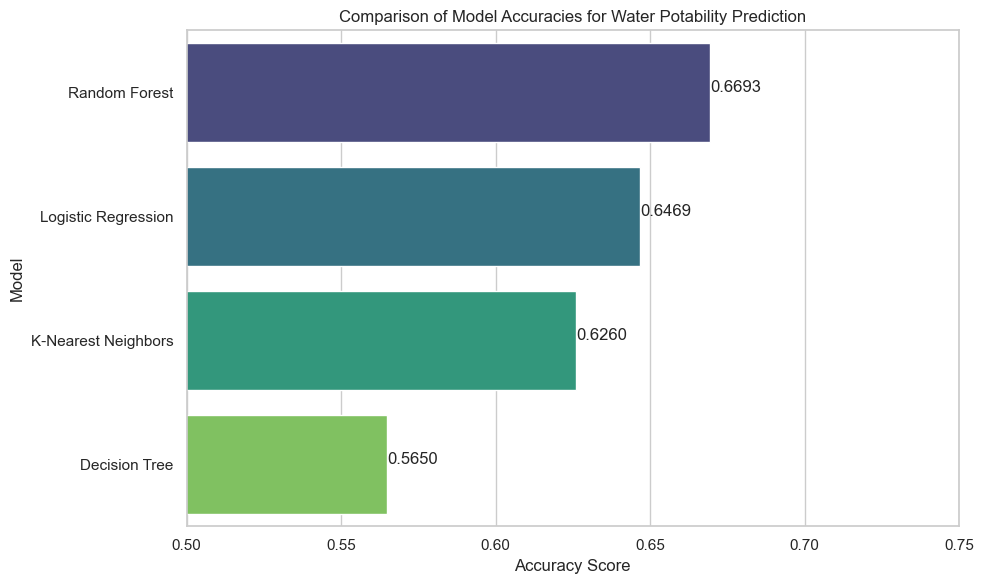

In [ ]:
# Plotting the accuracies
plt.figure(figsize=(10, 6))
sns.barplot(x='Accuracy', y='Model', data=accuracy_df_sorted, palette='viridis')
plt.xlabel('Accuracy Score')
plt.ylabel('Model')
plt.title('Comparison of Model Accuracies for Water Potability Prediction')
plt.xlim(0.5, 0.75)
for index, value in enumerate(accuracy_df_sorted['Accuracy']):
    plt.text(value, index, f'{value:.4f}')
plt.tight_layout()
plt.savefig('model_accuracy_comparison.png')
print("\nComparison plot saved as 'model_accuracy_comparison.png'")